In [9]:
from pathlib import Path
import pandas as pd
import numpy as np
from joblib import Parallel, delayed
from collections import defaultdict

In [11]:
ROOT = Path().cwd()
DATA_INITIAL = Path("../data_initial").resolve()
DATA = Path("../data").resolve()
FANTOM = DATA / "fantom_cat"
PREPROCESSING = Path("../preprocessing")
IPS = DATA_INITIAL / "deg/rnaseq_res_ips"
FIBRO = DATA_INITIAL / "deg/rnaseq_res_fibro"
IPS_INDEX = PREPROCESSING / "deg_index/ips_deg_index"
FIBRO_INDEX = PREPROCESSING / "deg_index/fibro_deg_index"
BIOMART = DATA / "biomart"
BIOMART_INITIAL = DATA_INITIAL / "biomart"
IPS_PREPROC = PREPROCESSING / "deg/fibro"
FIBRO_PREPROC = PREPROCESSING / "deg/ips"

In [ ]:
to_save = FIBRO_PREPROC / "fibro_df_with_deg_target_ens_genes_updated.tsv"
fibro_df_with_deg_target_ens_genes_updated.to_csv(to_save, sep="\t", index=False)
to_save = IPS_PREPROC / "ips_df_with_deg_target_ens_genes_updated.tsv"
ips_df_with_deg_target_ens_genes_updated.to_csv(to_save, sep="\t", index=False)

In [15]:
to_ips = IPS_PREPROC / "ips_df_with_deg_target_ens_genes_updated.tsv"
ips_expr_filt = pd.read_csv(to_ips, sep="\t")
ips_expr_filt.head()

,DEG.ens_gene,DEG.gene_name,log2FC,pvalue,fdr,ZScore,target.aso,target.ens_gene,target.gene_name,up_or_down_expr,DEG.ens_gene-new,DEG.gene_name-new,target.ens_gene-new,target.gene_name-new
0,ENSG00000205531,NAP1L4,-0.691972,3.899614e-06,0.042455,-5.061144,G0234787_08,ENSG00000234787,LINC00458,down,ENSG00000205531,NAP1L4,ENSG00000234787,LINC00458
1,ENSG00000089916,GPATCH2L,-1.041246,3.913478e-05,0.043336,-3.953852,R0057746_03,CATG00000070943,CATG00000070943.1,down,ENSG00000089916,GPATCH2L,CATG00000070943,NaN
2,ENSG00000099194,SCD,-0.635000,2.054724e-07,0.000870,-2.709444,R0057746_03,CATG00000070943,CATG00000070943.1,down,ENSG00000099194,SCD,CATG00000070943,NaN
3,ENSG00000113161,HMGCR,-0.912822,1.601495e-05,0.029059,-3.682696,R0057746_03,CATG00000070943,CATG00000070943.1,down,ENSG00000113161,HMGCR,CATG00000070943,NaN
4,ENSG00000128829,EIF2AK4,-0.887877,2.397361e-07,0.000870,-4.709886,R0057746_03,CATG00000070943,CATG00000070943.1,down,ENSG00000128829,EIF2AK4,CATG00000070943,NaN


In [16]:
ips_expr_filt[ips_expr_filt["target.gene_name-new"] == "EMX2OS"]

,DEG.ens_gene,DEG.gene_name,log2FC,pvalue,fdr,ZScore,target.aso,target.ens_gene,target.gene_name,up_or_down_expr,DEG.ens_gene-new,DEG.gene_name-new,target.ens_gene-new,target.gene_name-new


In [6]:
ips_expr_filt.shape

(15629, 10)

In [17]:
ips_expr_filt["DEG.ens_gene"].nunique()

5359

In [5]:
to_fibro = FIBRO / "DESeq2_genes_ASO_all.tsv.gz"
fibro_expr = pd.read_csv(to_fibro, sep="\t")
fibro_expr.head(3)

,Description,ASO_CAGE,KD.geneSymbol,perturb_id,geneID,geneSymbol,baseMean,log2FC,pvalue,fdr,KD.tpm.ave,NC.tpm.ave,ZScore
0,Targeted lncRNA,2,A1BG-AS1,ASO_G0268895_01,ENSG00000200169,RNU5D-1,134.656674,-2.325717,1.640034e-11,2.548449e-07,3.026571,15.427402,-3.106205
1,Targeted lncRNA,2,A1BG-AS1,ASO_G0268895_01,ENSG00000138675,FGF5,1788.727654,-1.371879,7.814666e-11,6.071605e-07,75.054256,196.439355,-2.756217
2,Targeted lncRNA,2,A1BG-AS1,ASO_G0268895_01,ENSG00000252521,RNU5D-2P,108.388065,-1.925674,1.102746e-09,5.711854e-06,3.178508,12.249495,-2.534245


In [6]:
fibro_expr.shape

(5748772, 13)

In [7]:
fibro_expr[fibro_expr["KD.geneSymbol"] == "EMX2OS"]

,Description,ASO_CAGE,KD.geneSymbol,perturb_id,geneID,geneSymbol,baseMean,log2FC,pvalue,fdr,KD.tpm.ave,NC.tpm.ave,ZScore
1819639,Targeted lncRNA,4,EMX2OS,ASO_G0229847_01,ENSG00000103888,KIAA1199,4772.797244,-1.445836e+00,6.387961e-17,9.836821e-13,218.927014,609.139450,-2.653991
1819640,Targeted lncRNA,4,EMX2OS,ASO_G0229847_01,ENSG00000137801,THBS1,5308.614566,-7.162151e-01,5.458089e-09,4.202456e-05,388.551113,652.433498,-1.866900
1819641,Targeted lncRNA,4,EMX2OS,ASO_G0229847_01,ENSG00000180875,GREM2,174.591731,-1.160813e+00,1.414628e-08,7.261284e-05,9.628134,22.008310,-2.204441
1819642,Targeted lncRNA,4,EMX2OS,ASO_G0229847_01,ENSG00000013588,GPRC5A,263.456094,9.195215e-01,6.894113e-08,2.654061e-04,50.361054,26.980827,1.704213
1819643,Targeted lncRNA,4,EMX2OS,ASO_G0229847_01,ENSG00000186340,THBS2,1743.551026,-8.879763e-01,1.213042e-07,3.735927e-04,114.507265,216.504792,-2.683827
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1880716,Targeted lncRNA,4,EMX2OS,ASO_G0229847_AD_04,ENSG00000041982,TNC,6417.532691,-9.715824e-05,9.994240e-01,9.996856e-01,757.921777,765.216219,0.851308
1880717,Targeted lncRNA,4,EMX2OS,ASO_G0229847_AD_04,ENSG00000160124,CCDC58,400.399399,6.039930e-05,9.995172e-01,9.997134e-01,47.433070,47.751199,0.081230
1880718,Targeted lncRNA,4,EMX2OS,ASO_G0229847_AD_04,ENSG00000167394,ZNF668,154.178923,-5.865624e-05,9.996549e-01,9.997857e-01,18.157717,18.391969,-0.256141
1880719,Targeted lncRNA,4,EMX2OS,ASO_G0229847_AD_04,ENSG00000184216,IRAK1,737.483433,-8.771279e-05,9.997386e-01,9.998040e-01,89.424854,88.148352,-0.110994


In [10]:
fibro_expr_filt = fibro_expr.query("fdr < 0.05 & abs(ZScore) > 1.645 & abs(log2FC) > 0.5")
ips_expr_filt.reset_index(inplace=True, drop=True)
fibro_expr_filt.head()

,Description,ASO_CAGE,KD.geneSymbol,perturb_id,geneID,geneSymbol,baseMean,log2FC,pvalue,fdr,KD.tpm.ave,NC.tpm.ave,ZScore
0,Targeted lncRNA,2,A1BG-AS1,ASO_G0268895_01,ENSG00000200169,RNU5D-1,134.656674,-2.325717,1.640034e-11,2.548449e-07,3.026571,15.427402,-3.106205
1,Targeted lncRNA,2,A1BG-AS1,ASO_G0268895_01,ENSG00000138675,FGF5,1788.727654,-1.371879,7.814666e-11,6.071605e-07,75.054256,196.439355,-2.756217
2,Targeted lncRNA,2,A1BG-AS1,ASO_G0268895_01,ENSG00000252521,RNU5D-2P,108.388065,-1.925674,1.102746e-09,5.711854e-06,3.178508,12.249495,-2.534245
3,Targeted lncRNA,2,A1BG-AS1,ASO_G0268895_01,ENSG00000268895,A1BG-AS1,100.134784,-1.542280,3.509193e-09,1.363234e-05,3.802250,11.079833,-7.161737
4,Targeted lncRNA,2,A1BG-AS1,ASO_G0268895_01,CATG00000098831,CATG00000098831.1,163.640506,1.153985,1.174760e-08,3.480974e-05,27.770456,12.658186,2.301412


In [11]:
fibro_expr_filt.shape

(145540, 13)

TO DO:
1) Пересечь еще раз и переименовть таблицу с фибробластами
2) Переимновать ASO
3) Найти словарь миграции генов. Upd: нужно пересмотреть все шаги с переходом между сборками. Либо нужно использовать тул от ensembl, либо проверить, что после переноса liftover-ом у нас не было генов, id который вообще не имеет отнощения к grch38. Помимо координат нужно переносить еще и названия генов, если они изменялись
4) Спросить, нужно ли заново объединять химорну и рнк-хром. Ведь теперь у пиков из химорны другие координаты --Ответ (коордианты пиков не изменились, они и до этого были на GRCh38)

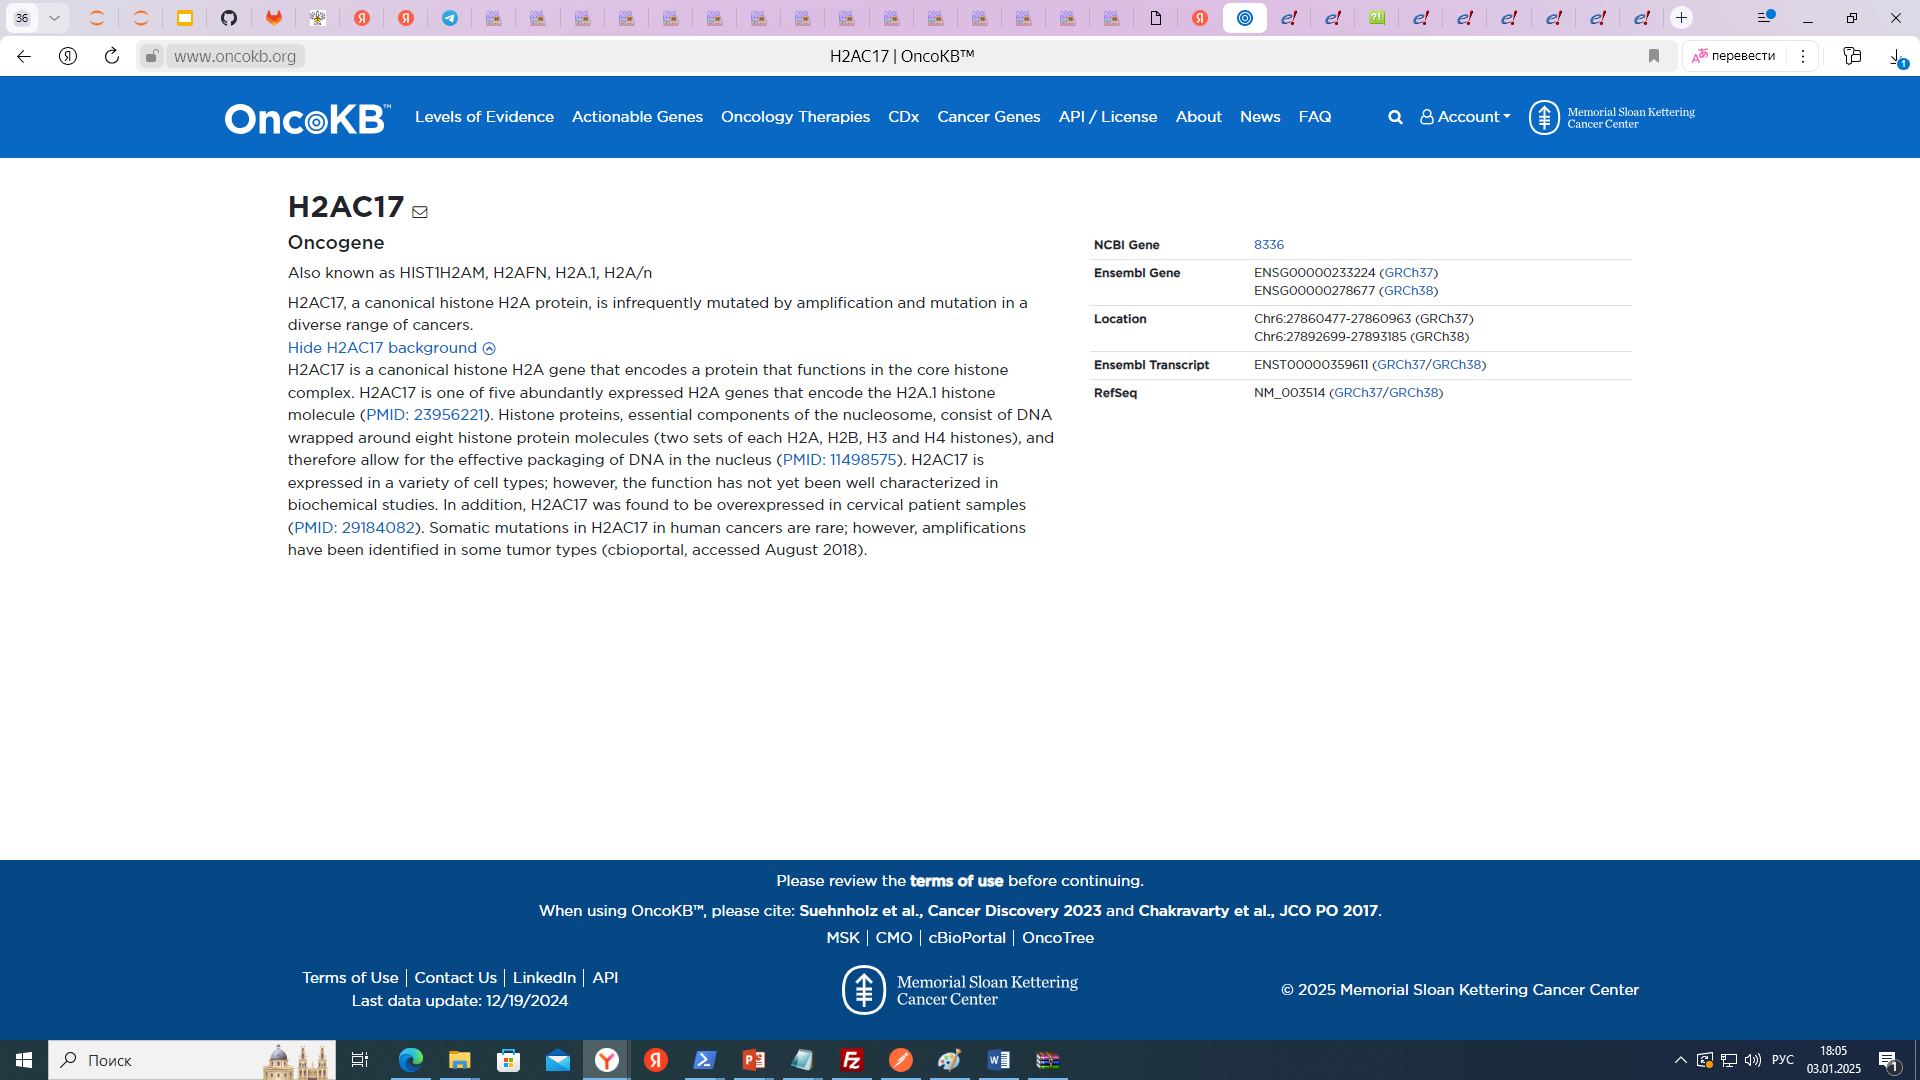

In [12]:
fibro_expr_filt["up_or_down_expr"] = np.where(fibro_expr_filt["log2FC"] > 0, "up", "down")

/tmp/ipykernel_209725/515906159.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fibro_expr_filt["up_or_down_expr"] = np.where(fibro_expr_filt["log2FC"] > 0, "up", "down")


In [13]:
to_fibro_aso = FIBRO / "ASO_names.info"
fibro_aso = pd.read_csv(to_fibro_aso, sep="\t")
fibro_aso.head()

,aso_id,aso_id_short,prmtrID,prmtrName,trnscptID,trnscptName,trnscptType,geneID,geneName,geneType
0,ASO_C0000830_02,C0000830,CUFT00000000830.T0,chr1_50977446_50977745_+,p012@CDKN2C,CUFT00000000830.T0,__na,ENSG00000123080,CDKN2C,protein_coding
1,ASO_C0000830_08,C0000830,CUFT00000000830.T0,chr1_50977446_50977745_+,p012@CDKN2C,CUFT00000000830.T0,__na,ENSG00000123080,CDKN2C,protein_coding
2,ASO_C0008202_01,C0008202,CUFT00000008202.T0,chr4_183350680_183350979_-,p003@CLDN22,CUFT00000008202.T0,__na,ENSG00000177300,CLDN22,protein_coding
3,ASO_C0008202_02,C0008202,CUFT00000008202.T0,chr4_183350680_183350979_-,p003@CLDN22,CUFT00000008202.T0,__na,ENSG00000177300,CLDN22,protein_coding
4,ASO_C0008202_04,C0008202,CUFT00000008202.T0,chr4_183350680_183350979_-,p003@CLDN22,CUFT00000008202.T0,__na,ENSG00000177300,CLDN22,protein_coding


In [14]:
fibro_expr_filt = pd.merge(left=fibro_expr_filt, left_on="perturb_id",
         right=fibro_aso[["aso_id", "geneID"]], right_on="aso_id")
fibro_expr_filt.head()

,Description,ASO_CAGE,KD.geneSymbol,perturb_id,geneID_x,geneSymbol,baseMean,log2FC,pvalue,fdr,KD.tpm.ave,NC.tpm.ave,ZScore,up_or_down_expr,aso_id,geneID_y
0,Targeted lncRNA,2,A1BG-AS1,ASO_G0268895_01,ENSG00000200169,RNU5D-1,134.656674,-2.325717,1.640034e-11,2.548449e-07,3.026571,15.427402,-3.106205,down,ASO_G0268895_01,ENSG00000268895
1,Targeted lncRNA,2,A1BG-AS1,ASO_G0268895_01,ENSG00000138675,FGF5,1788.727654,-1.371879,7.814666e-11,6.071605e-07,75.054256,196.439355,-2.756217,down,ASO_G0268895_01,ENSG00000268895
2,Targeted lncRNA,2,A1BG-AS1,ASO_G0268895_01,ENSG00000252521,RNU5D-2P,108.388065,-1.925674,1.102746e-09,5.711854e-06,3.178508,12.249495,-2.534245,down,ASO_G0268895_01,ENSG00000268895
3,Targeted lncRNA,2,A1BG-AS1,ASO_G0268895_01,ENSG00000268895,A1BG-AS1,100.134784,-1.542280,3.509193e-09,1.363234e-05,3.802250,11.079833,-7.161737,down,ASO_G0268895_01,ENSG00000268895
4,Targeted lncRNA,2,A1BG-AS1,ASO_G0268895_01,CATG00000098831,CATG00000098831.1,163.640506,1.153985,1.174760e-08,3.480974e-05,27.770456,12.658186,2.301412,up,ASO_G0268895_01,ENSG00000268895


In [15]:
fibro_expr_filt.shape

(141906, 16)

In [16]:
ips_expr_filt.head(1)

,DEG.geneID,DEG.HGNC,EdgeR.log2FC,EdgeR.log2CPM,EdgeR.pvalue,EdgeR.FDR,EdgeR.Zscore,target.gapmerID,target.geneID,target.HGNC,up_or_down_expr
0,ENSG00000205531,NAP1L4,-0.691972,7.349218,0.000004,0.042455,-5.061144,G0234787_08,ENSG00000234787,LINC00458,down


In [17]:
fibro_expr_filt.rename(columns={"geneID":"DEG.geneID", "":"DEG.HGNC",
                                "perturb_id":"target.gapmerID", "KD.geneSymbol":"target.geneID", "":"target.HGNC"}, inplace=True)

In [19]:
deg_results = {"ips":   ips_expr_filt,
               "fibro": fibro_expr_filt}

In [28]:
deg_results["ips"]

,DEG.geneID,DEG.HGNC,EdgeR.log2FC,EdgeR.log2CPM,EdgeR.pvalue,EdgeR.FDR,EdgeR.Zscore,target.gapmerID,target.geneID,target.HGNC,up_or_down_expr
0,ENSG00000205531,NAP1L4,-0.691972,7.349218,3.899614e-06,0.042455,-5.061144,G0234787_08,ENSG00000234787,LINC00458,down
1,ENSG00000089916,GPATCH2L,-1.041246,5.600935,3.913478e-05,0.043336,-3.953852,R0057746_03,CATG00000070943,CATG00000070943.1,down
2,ENSG00000099194,SCD,-0.635000,8.662415,2.054724e-07,0.000870,-2.709444,R0057746_03,CATG00000070943,CATG00000070943.1,down
3,ENSG00000113161,HMGCR,-0.912822,6.861125,1.601495e-05,0.029059,-3.682696,R0057746_03,CATG00000070943,CATG00000070943.1,down
4,ENSG00000128829,EIF2AK4,-0.887877,6.605389,2.397361e-07,0.000870,-4.709886,R0057746_03,CATG00000070943,CATG00000070943.1,down
...,...,...,...,...,...,...,...,...,...,...,...
15624,ENSG00000259203,RP11-209K10.2,1.364151,3.400504,6.251776e-05,0.003601,1.693698,G0230844_AD_07,ENSG00000230844,ZNF674-AS1,up
15625,ENSG00000262481,TMEM256-PLSCR3,-0.742945,6.773472,4.097390e-04,0.013477,-2.084815,G0230844_AD_07,ENSG00000230844,ZNF674-AS1,down
15626,ENSG00000265381,AL121987.1,0.914705,5.526066,1.590841e-06,0.000224,2.369778,G0230844_AD_07,ENSG00000230844,ZNF674-AS1,up
15627,ENSG00000265565,MIR3143,-0.673589,10.525010,3.604504e-05,0.002453,-3.019324,G0230844_AD_07,ENSG00000230844,ZNF674-AS1,down


In [34]:
deg_results["ips"]["target.geneID"].nunique(), deg_results["ips"]["target.gapmerID"].nunique()

(119, 259)

In [30]:
deg_results["fibro"]

,Description,ASO_CAGE,target.geneID,target.gapmerID,geneID_x,geneSymbol,baseMean,log2FC,pvalue,fdr,KD.tpm.ave,NC.tpm.ave,ZScore,up_or_down_expr,aso_id,geneID_y
0,Targeted lncRNA,2,A1BG-AS1,ASO_G0268895_01,ENSG00000200169,RNU5D-1,134.656674,-2.325717,1.640034e-11,2.548449e-07,3.026571,15.427402,-3.106205,down,ASO_G0268895_01,ENSG00000268895
1,Targeted lncRNA,2,A1BG-AS1,ASO_G0268895_01,ENSG00000138675,FGF5,1788.727654,-1.371879,7.814666e-11,6.071605e-07,75.054256,196.439355,-2.756217,down,ASO_G0268895_01,ENSG00000268895
2,Targeted lncRNA,2,A1BG-AS1,ASO_G0268895_01,ENSG00000252521,RNU5D-2P,108.388065,-1.925674,1.102746e-09,5.711854e-06,3.178508,12.249495,-2.534245,down,ASO_G0268895_01,ENSG00000268895
3,Targeted lncRNA,2,A1BG-AS1,ASO_G0268895_01,ENSG00000268895,A1BG-AS1,100.134784,-1.542280,3.509193e-09,1.363234e-05,3.802250,11.079833,-7.161737,down,ASO_G0268895_01,ENSG00000268895
4,Targeted lncRNA,2,A1BG-AS1,ASO_G0268895_01,CATG00000098831,CATG00000098831.1,163.640506,1.153985,1.174760e-08,3.480974e-05,27.770456,12.658186,2.301412,up,ASO_G0268895_01,ENSG00000268895
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
141901,Positive Control,3,ZNF730,ASO_G0267886_AD_04,ENSG00000232187,FTH1P7,26.644841,2.554486,3.241567e-05,4.609803e-02,8.950265,2.698157,5.237118,up,ASO_G0267886_AD_04,ENSG00000183850
141902,Targeted lncRNA,2,ZSCAN16-AS1,ASO_G0269293_01,ENSG00000142961,MOB3C,71.003607,0.749422,6.254070e-06,4.815008e-02,14.886614,8.975384,3.582150,up,ASO_G0269293_01,ENSG00000269293
141903,Targeted lncRNA,2,ZSCAN16-AS1,ASO_G0269293_AD_10,ENSG00000132613,MTSS1L,867.903141,-0.535628,1.170372e-06,1.853869e-02,76.849027,113.042453,-1.732862,down,ASO_G0269293_AD_10,ENSG00000269293
141904,Targeted lncRNA,2,ZSCAN16-AS1,ASO_G0269293_AD_10,ENSG00000264395,MIR3193,14.064713,1.530984,4.610931e-06,3.651857e-02,4.272252,1.527248,2.419552,up,ASO_G0269293_AD_10,ENSG00000269293


In [35]:
deg_results["fibro"]["target.geneID"].nunique(), deg_results["fibro"]["target.gapmerID"].nunique()

(154, 303)

Так как предыдущая версия Himorna была сделана на GRCh37, то и gene name для генов lncRNA также имеют прошлую натацию. Для обновления, воспользуемся biomart: \
https://grch37.ensembl.org/biomart/martview \
https://www.ensembl.org/biomart/martview \
Агрегированная таблица GRCh37/GRCh38 находится тут: \
/export/home/agletdinov/work/git_projects/fantom.deg-himorna.peaks/data/biomart/mart_export-GRCh37_to_GRCh38.tsv.gz

In [8]:
to_table = BIOMART / f"mart_export-GRCh37_to_GRCh38.tsv.gz"
biomart_merged = pd.read_csv(to_table, sep="\t")
biomart_merged.head()

,gene_ens,gene_name-GRCh37,gene_name-GRCh38
0,ENSG00000000003,TSPAN6,TSPAN6
1,ENSG00000000005,TNMD,TNMD
2,ENSG00000000419,DPM1,DPM1
3,ENSG00000000457,SCYL3,SCYL3
4,ENSG00000000460,C1orf112,FIRRM


In [10]:
biomart_merged.shape

(96427, 3)

In [13]:
biomart_merged[biomart_merged["gene_ens"] == "ENSG00000229847"]

,gene_ens,gene_name-GRCh37,gene_name-GRCh38
31745,ENSG00000229847,EMX2OS,EMX2OS


In [42]:
deg_results["ips"]

,DEG.geneID,DEG.HGNC,EdgeR.log2FC,EdgeR.log2CPM,EdgeR.pvalue,EdgeR.FDR,EdgeR.Zscore,target.gapmerID,target.geneID,target.HGNC,up_or_down_expr
0,ENSG00000205531,NAP1L4,-0.691972,7.349218,3.899614e-06,0.042455,-5.061144,G0234787_08,ENSG00000234787,LINC00458,down
1,ENSG00000089916,GPATCH2L,-1.041246,5.600935,3.913478e-05,0.043336,-3.953852,R0057746_03,CATG00000070943,CATG00000070943.1,down
2,ENSG00000099194,SCD,-0.635000,8.662415,2.054724e-07,0.000870,-2.709444,R0057746_03,CATG00000070943,CATG00000070943.1,down
3,ENSG00000113161,HMGCR,-0.912822,6.861125,1.601495e-05,0.029059,-3.682696,R0057746_03,CATG00000070943,CATG00000070943.1,down
4,ENSG00000128829,EIF2AK4,-0.887877,6.605389,2.397361e-07,0.000870,-4.709886,R0057746_03,CATG00000070943,CATG00000070943.1,down
...,...,...,...,...,...,...,...,...,...,...,...
15624,ENSG00000259203,RP11-209K10.2,1.364151,3.400504,6.251776e-05,0.003601,1.693698,G0230844_AD_07,ENSG00000230844,ZNF674-AS1,up
15625,ENSG00000262481,TMEM256-PLSCR3,-0.742945,6.773472,4.097390e-04,0.013477,-2.084815,G0230844_AD_07,ENSG00000230844,ZNF674-AS1,down
15626,ENSG00000265381,AL121987.1,0.914705,5.526066,1.590841e-06,0.000224,2.369778,G0230844_AD_07,ENSG00000230844,ZNF674-AS1,up
15627,ENSG00000265565,MIR3143,-0.673589,10.525010,3.604504e-05,0.002453,-3.019324,G0230844_AD_07,ENSG00000230844,ZNF674-AS1,down


In [79]:
for exp in deg_results:
    deg_results[exp] = pd.merge(left=deg_results[exp], right=biomart_merged,
                                left_on="DEG.geneID", right_on="gene_ens", how="left")

In [82]:
s = deg_results["fibro"][["DEG.geneID", "DEG.HGNC","gene_name-GRCh37","gene_name-GRCh38"]]

KeyError: "['DEG.HGNC'] not in index"

In [83]:
np.sum(~(s["DEG.HGNC"] == s["gene_name-GRCh38"]))

1232

In [76]:
mask = ~(s["DEG.HGNC"] == s["gene_name-GRCh38"])
s[mask]

,DEG.geneID,DEG.HGNC,gene_name-GRCh37,gene_name-GRCh38
16,ENSG00000233224,HIST1H2AM,HIST1H2AM,NaN
30,ENSG00000267040,RP11-35G9.3,RP11-35G9.3,ATP8B1-AS1
31,CATG00000041529,CATG00000041529.1,NaN,NaN
32,CATG00000064155,CATG00000064155.1,NaN,NaN
85,ENSG00000233224,HIST1H2AM,HIST1H2AM,NaN
...,...,...,...,...
15619,ENSG00000256316,HIST1H3F,HIST1H3F,NaN
15623,ENSG00000259132,RP11-298I3.5,RP11-298I3.5,NaN
15624,ENSG00000259203,RP11-209K10.2,RP11-209K10.2,NaN
15626,ENSG00000265381,AL121987.1,AL121987.1,NaN


In [77]:
s[s["DEG.geneID"] == "ENSG00000233224"]

,DEG.geneID,DEG.HGNC,gene_name-GRCh37,gene_name-GRCh38
16,ENSG00000233224,HIST1H2AM,HIST1H2AM,NaN
85,ENSG00000233224,HIST1H2AM,HIST1H2AM,NaN
711,ENSG00000233224,HIST1H2AM,HIST1H2AM,NaN
3458,ENSG00000233224,HIST1H2AM,HIST1H2AM,NaN
4653,ENSG00000233224,HIST1H2AM,HIST1H2AM,NaN
5326,ENSG00000233224,HIST1H2AM,HIST1H2AM,NaN
5584,ENSG00000233224,HIST1H2AM,HIST1H2AM,NaN
6776,ENSG00000233224,HIST1H2AM,HIST1H2AM,NaN
6954,ENSG00000233224,HIST1H2AM,HIST1H2AM,NaN
7852,ENSG00000233224,HIST1H2AM,HIST1H2AM,NaN


In [ ]:
Ensembl Gene	
ENSG00000233224 (
GRCh37
)
ENSG00000278677 (
GRCh38
)

In [21]:
def indexing_deg(lnc_ens, aso, up_or_down_expr, subdf, project_dir):
    to_index = Path(project_dir) / lnc_ens
    to_index.mkdir(exist_ok=True, parents=True)
    to_save = to_index / f"{lnc_ens}-{aso}-{up_or_down_expr}-.tsv.gz"
    if to_save.exists():
        print(f"Skipped: {lnc_ens} {aso} {up_or_down_expr} {project_dir.stem}")
        return None
    subdf.to_csv(to_save, sep="\t", compression="gzip", index=False)    

In [26]:
with Parallel(n_jobs=-1) as pool:
        chunks = pool(
            delayed(indexing_deg)(lnc_ens, aso, up_or_down_expr, subdf, project_dir=PREPROCESSING / f"deg_index/{exp}_deg_index")
            for exp in deg_results
            for (lnc_ens, aso, up_or_down_expr), subdf in deg_results[exp].groupby(by=["target.geneID", "target.gapmerID", "up_or_down_expr"])
        )

In [27]:
#способ смотреть без разбиаения на up/down экспрессию
pd.concat([pd.read_csv(to_deg, sep="\t") for to_deg in IPS_INDEX.glob((f'*/*ENSG00000142396-G0142396_AD_01-*'))]).head()

,DEG.geneID,DEG.HGNC,EdgeR.log2FC,EdgeR.log2CPM,EdgeR.pvalue,EdgeR.FDR,EdgeR.Zscore,target.gapmerID,target.geneID,target.HGNC,up_or_down_expr
0,ENSG00000067113,PLPP1,-0.768020,6.016004,0.000133,0.032065,-2.639597,G0142396_AD_01,ENSG00000142396,ERVK3-1,down
1,ENSG00000071054,MAP4K4,-0.547953,7.187303,0.000127,0.031478,-3.879051,G0142396_AD_01,ENSG00000142396,ERVK3-1,down
2,ENSG00000078140,UBE2K,-0.536019,7.982436,0.000162,0.033866,-3.795072,G0142396_AD_01,ENSG00000142396,ERVK3-1,down
3,ENSG00000101856,PGRMC1,-0.601067,7.721209,0.000080,0.022462,-2.658966,G0142396_AD_01,ENSG00000142396,ERVK3-1,down
4,ENSG00000113269,RNF130,-0.778662,6.261279,0.000012,0.006001,-3.515180,G0142396_AD_01,ENSG00000142396,ERVK3-1,down


In [28]:
#способ смотреть без разбиаения на up/down экспрессию
pd.concat([pd.read_csv(to_deg, sep="\t") for to_deg in FIBRO_INDEX.glob((f'*/*ENSG00000240875-ASO_G0240875_10-*'))]).head()

,Description,ASO_CAGE,KD.geneSymbol,target.gapmerID,DEG.geneID,geneSymbol,baseMean,log2FC,pvalue,fdr,KD.tpm.ave,NC.tpm.ave,ZScore,up_or_down_expr,aso_id,target.geneID
0,Targeted lncRNA,5,LINC00886,ASO_G0240875_10,ENSG00000111144,LTA4H,581.340647,0.643336,5.975901e-10,0.000002,91.036450,58.205364,2.405249,up,ASO_G0240875_10,ENSG00000240875
1,Targeted lncRNA,5,LINC00886,ASO_G0240875_10,ENSG00000197958,RPL12,1002.370844,1.634219,3.039196e-06,0.002936,241.765335,78.679979,2.625141,up,ASO_G0240875_10,ENSG00000240875
2,Targeted lncRNA,5,LINC00886,ASO_G0240875_10,ENSG00000165072,MAMDC2,113.664940,0.786023,3.527888e-06,0.003208,19.069115,11.063988,2.177767,up,ASO_G0240875_10,ENSG00000240875
3,Targeted lncRNA,5,LINC00886,ASO_G0240875_10,ENSG00000137509,PRCP,588.642425,0.528597,4.065014e-06,0.003411,86.973439,60.296739,2.395984,up,ASO_G0240875_10,ENSG00000240875
4,Targeted lncRNA,5,LINC00886,ASO_G0240875_10,ENSG00000104435,STMN2,320.378413,0.519063,1.043377e-05,0.006452,47.048641,32.882947,1.930233,up,ASO_G0240875_10,ENSG00000240875
